# Playground: scaling-law sweep (week-02)

Interactive scratchpad for the 4-model scaling sweep in `src/scaling_configs.py` / `src/train.py`.
Run `src/run_all.py` first (it trains all 4 configs and writes `results/<run_name>/{model_weights.pt, loss_history.json, config.json, best_checkpoint.pt}` plus `results/scaling_table.{md,json}`), then `src/fit_scaling_law.py` (writes `results/scaling_law_fit.json`, `results/scaling_law_fit.png`, `results/compute_frontier.png`) - this notebook only loads and explores those results, it doesn't train or fit anything itself.

The 4 runs (only `d_model` varies - `num_layers=2`, `num_heads=4`, `block_size=128` fixed across all of them, see `scaling_configs.py` for why):
- **scale_100k** - target N ~= 100,000
- **scale_250k** - target N ~= 250,000
- **scale_500k** - target N ~= 500,000
- **scale_1m** - target N ~= 1,000,000

Sections:
1. Setup - load the tokenizer and imports
2. Discover runs + reconstruct models generically from `config.json`
3. Parameter-count sanity table - target vs. live-recounted vs. % off
4. Loss curves per run
5. Scaling-law fit - L(N) = L_inf + A*N^-alpha, with the df=1 CI caveat
6. Compute-optimal frontier
7. Text-generation playground - same prompt, all 4 model sizes side by side
8. Scratch space


## 1. Setup

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

# Notebook lives in notebooks/, project code in src/ - adjust if you move this file.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC_DIR = PROJECT_ROOT / "src"
RESULTS_DIR = PROJECT_ROOT / "results"
DATA_DIR = PROJECT_ROOT / "data"

# main.py isn't in this week's src/ - it's imported from week-1's src/ (same fragile sibling-path
# hack train.py uses, see that file's comment for why there's no cleaner option here). This is
# inserted *before* SRC_DIR below so that week-1's src/ is searched first for 'main' (which only
# exists there) - but since both weeks also have their own train.py/data_download.py of the same
# name, SRC_DIR is inserted afterwards (ending up at sys.path[0], i.e. searched *first*) so that
# 'import train'/'import data_download' below resolve to *this* week's versions, not week-1's.
WEEK1_SRC = PROJECT_ROOT.parent / "week-01-transformers" / "src"
sys.path.insert(0, str(WEEK1_SRC))
sys.path.insert(0, str(SRC_DIR))

from main import Transformer
from flops import load_run
from train import SUBSAMPLE_CHARS  # noqa: E402 - importing train.py runs `matplotlib.use('Agg')`
# at module level (train.py needs a headless-safe backend to run as a plain script), which would
# otherwise silently clobber the interactive inline backend this notebook wants - so %matplotlib
# inline is set *after* this import, not before, to override that and get real inline plots below.
%matplotlib inline

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"device: {device}")

device: cuda


Tokenizer - must match `train.py` exactly: same source file, same character-level `sorted(set(text))` vocab, and critically the **same subsample** (`SUBSAMPLE_CHARS`, imported above from `train.py` so it can never drift out of sync with what the models were actually trained on).

In [2]:
text = (DATA_DIR / "TinyStories-valid.txt").read_text()
text = text[:SUBSAMPLE_CHARS]  # must match train.py's subsampling exactly - see note above

chars = sorted(set(text))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: ''.join(itos[i] for i in ids)

print(f"subsampled to {len(text):,} characters, vocab_size: {vocab_size}")
print(''.join(chars))

subsampled to 5,000,000 characters, vocab_size: 90

 !"&'*,-./0123456789:;<>?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz|éñ –—‘’“”…🎓


## 2. Discover runs + reconstruct models

Load every scaling run found under `results/` (each run's `config.json` records the exact hyperparameters *and* the live parameter count it was trained with, so models are reconstructed generically - no hardcoding `d_model` etc. here, and no risk of it drifting out of sync with `scaling_configs.py`).

In [3]:
PREFERRED_ORDER = ["scale_100k", "scale_250k", "scale_500k", "scale_1m"]
run_dirs = sorted(
    (d for d in RESULTS_DIR.iterdir() if d.is_dir() and (d / "config.json").exists()),
    key=lambda d: PREFERRED_ORDER.index(d.name) if d.name in PREFERRED_ORDER else len(PREFERRED_ORDER),
)
assert run_dirs, f"No scaling runs found under {RESULTS_DIR} - run src/run_all.py first."

runs = {}
for run_dir in run_dirs:
    config = json.loads((run_dir / "config.json").read_text())
    model = Transformer(
        d_model=config["d_model"],
        num_layers=config["num_layers"],
        num_heads=config["num_heads"],
        vocab_size=config["vocab_size"],
        block_size=config["block_size"],
        positional_embedding_type=config["positional_embedding_type"],
        norm_type=config["norm_type"],
        mlp_type=config["mlp_type"],
    ).to(device)
    model.load_state_dict(torch.load(run_dir / "model_weights.pt", map_location=device))
    model.eval()

    loss_history = json.loads((run_dir / "loss_history.json").read_text())

    runs[run_dir.name] = {"model": model, "config": config, "loss_history": loss_history}
    n_params = sum(p.numel() for p in model.parameters())
    print(f"Loaded '{run_dir.name}': d_model={config['d_model']:<4} live N={n_params:,} "
          f"(config.json says {config['n_params']:,})")

# Fixed color per run - same color always means the same run across every plot below.
RUN_COLORS = {
    "scale_100k": "#2a78d6",  # blue
    "scale_250k": "#eb6834",  # orange
    "scale_500k": "#1baf7a",  # aqua
    "scale_1m": "#eda100",    # yellow
}

Loaded 'scale_100k': d_model=60   live N=100,680 (config.json says 100,680)
Loaded 'scale_250k': d_model=96   live N=244,032 (config.json says 244,032)
Loaded 'scale_500k': d_model=140  live N=503,720 (config.json says 503,720)


Loaded 'scale_1m': d_model=200  live N=1,007,600 (config.json says 1,007,600)


## 3. Parameter-count sanity table

Compares the pre-training estimate (`scaling_configs.estimate_params`, derived from the hand-worked formula in that file's docstring) against the actual live-recounted parameter count of the constructed model (`sum(p.numel() for p in model.parameters())`, which correctly dedupes the tied embedding/head weight) and the original target N. All three should be close - this is a sanity check that the formula derivation was right and that weight tying is actually working, not just a formality.

In [4]:
from scaling_configs import estimate_params, SCALING_RUNS

target_by_name = {c["run_name"]: c["target_n"] for c in SCALING_RUNS}

print(f"{'run':<12} {'target N':>10} {'formula est.':>13} {'live count':>12} {'% off target':>13}")
for run_name, run in runs.items():
    cfg = run["config"]
    live_n = sum(p.numel() for p in run["model"].parameters())
    est_n = estimate_params(cfg["d_model"], vocab_size=cfg["vocab_size"], block_size=cfg["block_size"],
                             num_layers=cfg["num_layers"])
    target_n = target_by_name.get(run_name)
    pct_off = 100 * (live_n - target_n) / target_n if target_n else float("nan")
    print(f"{run_name:<12} {target_n:>10,} {est_n:>13,} {live_n:>12,} {pct_off:>12.1f}%")

run            target N  formula est.   live count  % off target
scale_100k      100,000       100,680      100,680          0.7%
scale_250k      250,000       244,032      244,032         -2.4%
scale_500k      500,000       503,720      503,720          0.7%
scale_1m      1,000,000     1,007,600    1,007,600          0.8%


## 4. Loss curves per run

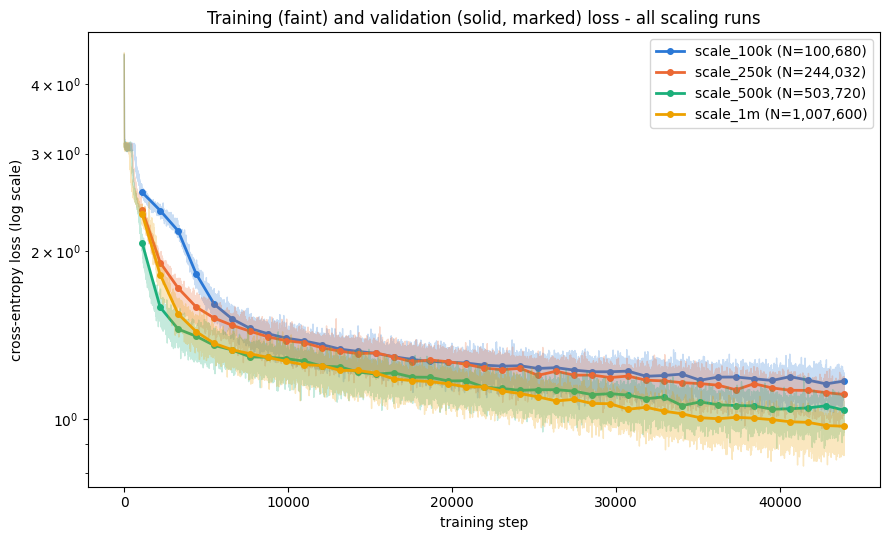

run            target N  achieved N  final val loss  flops @ best  wall-clock (s)
scale_100k      100,000     100,680          1.1555     1.060e+14          1029.9
scale_250k      250,000     244,032          1.1062     2.634e+14          1135.0
scale_500k      500,000     503,720          1.0363     5.437e+14          1698.7
scale_1m      1,000,000   1,007,600          0.9697     1.088e+15          2482.1


In [5]:
plt.figure(figsize=(9, 5.5))
for run_name, run in runs.items():
    color = RUN_COLORS.get(run_name, "#4a3aa7")
    history = run["loss_history"]
    train_steps, train_vals = zip(*history["train"])
    val_steps, val_vals = zip(*history["val"])
    n_params = run["config"]["n_params"]
    plt.plot(train_steps, train_vals, color=color, alpha=0.25, linewidth=1)  # faint - noisy per-step train loss
    plt.plot(val_steps, val_vals, color=color, linewidth=2, marker='o', markersize=4,
              label=f"{run_name} (N={n_params:,})")

plt.yscale('log')
plt.xlabel('training step')
plt.ylabel('cross-entropy loss (log scale)')
plt.title('Training (faint) and validation (solid, marked) loss - all scaling runs')
plt.legend()
plt.tight_layout()
plt.show()

# --- Table of final results (written by run_all.py) ---
table_path = RESULTS_DIR / "scaling_table.json"
if table_path.exists():
    table = json.loads(table_path.read_text())
    print(f"{'run':<12} {'target N':>10} {'achieved N':>11} {'final val loss':>15} {'flops @ best':>13} {'wall-clock (s)':>15}")
    for row in table:
        print(f"{row['run_name']:<12} {row['target_n']:>10,} {row['n_params']:>11,} "
              f"{row['final_val_loss']:>15.4f} {row['flops_at_best']:>13.3e} {row['wall_clock_seconds']:>15.1f}")
else:
    print(f"No {table_path} found - it's written at the end of run_all.py.")

## 5. Scaling-law fit

`L(N) = L_inf + A*N^-alpha`, fit by nonlinear least squares (see `src/fit_scaling_law.py` for the full derivation of the initial guesses and why this can't just be a log-log linear fit). The important caveat, printed explicitly below: with 4 data points and 3 free parameters there is exactly **1 residual degree of freedom**, so the 95% CI on alpha is ~12.7x wider than the usual large-sample 1.96x-SE rule of thumb (`t.ppf(0.975, df=1) ~= 12.7`). alpha here is a rough trend indicator, not a tightly pinned-down exponent.

In [6]:
fit_path = RESULTS_DIR / "scaling_law_fit.json"
assert fit_path.exists(), f"{fit_path} not found - run src/fit_scaling_law.py first."
fit_results = json.loads(fit_path.read_text())

full_fit = fit_results["full_fit"]
simple_fit = fit_results["simple_fit"]

print(f"Full fit   L(N) = L_inf + A*N^-alpha:")
print(f"  alpha = {full_fit['alpha']:.4f}  (SE = {full_fit['alpha_se']:.4f})")
print(f"  95% CI (df=1, t-multiplier={full_fit['t_multiplier_df1']:.2f}): "
      f"[{full_fit['alpha_ci95'][0]:.4f}, {full_fit['alpha_ci95'][1]:.4f}]")
print(f"  L_inf = {full_fit['L_inf']:.4f}, A = {full_fit['A']:.4g}")
print(f"\n  CAVEAT: {full_fit['caveat']}")

print(f"\nSimple fit  L(N) = A*N^-alpha  (L_inf pinned to 0, plain OLS on log-log, sanity check):")
print(f"  alpha = {simple_fit['alpha']:.4f}  (R^2 = {simple_fit['r_squared']:.4f}, "
      f"df={simple_fit['degrees_of_freedom']})")

print(f"\nKaplan et al. (2020) report alpha ~= {fit_results['kaplan_alpha_reference']} "
      f"for their token-level BPE-tokenized web-text sweep - see notes.md for why ours differs.")

Full fit   L(N) = L_inf + A*N^-alpha:
  alpha = 0.0756  (SE = 0.4521)
  95% CI (df=1, t-multiplier=12.71): [-5.6689, 5.8201]
  L_inf = 0.0000, A = 2.785

  CAVEAT: With 4 data points and 3 free parameters (L_inf, A, alpha), there is exactly 1 residual degree of freedom. The 95% CI here uses the t-distribution at df=1 (t.ppf(0.975, df=1)=12.71), not the usual normal-approximation 1.96x - about 12.7x wider than a naive large-sample CI would report. This means alpha is poorly constrained *by design*, not that anything went wrong: with only 4 points, there's essentially no slack left to independently estimate uncertainty once 3 parameters are fit to it. Take alpha's point estimate as a rough indication of trend, not a tightly pinned-down exponent.

Simple fit  L(N) = A*N^-alpha  (L_inf pinned to 0, plain OLS on log-log, sanity check):
  alpha = 0.0768  (R^2 = 0.9774, df=2)

Kaplan et al. (2020) report alpha ~= 0.076 for their token-level BPE-tokenized web-text sweep - see notes.md for why 

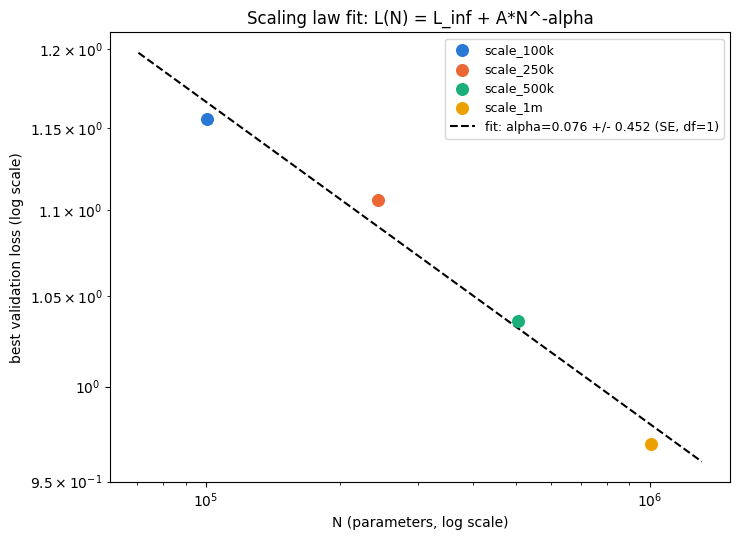

In [7]:
def power_law(N, L_inf, A, alpha):
    return L_inf + A * np.power(N, -alpha)


N_arr = np.array(fit_results["N"], dtype=float)
L_arr = np.array(fit_results["L"], dtype=float)

plt.figure(figsize=(7.5, 5.5))
for run_name, N, L in zip(fit_results["run_names"], N_arr, L_arr):
    plt.scatter([N], [L], color=RUN_COLORS.get(run_name, "#4a3aa7"), s=70, zorder=3, label=run_name)

N_smooth = np.geomspace(N_arr.min() * 0.7, N_arr.max() * 1.3, 200)
plt.plot(N_smooth, power_law(N_smooth, *full_fit["popt"]), color="black", linewidth=1.5, linestyle="--",
          label=f"fit: alpha={full_fit['alpha']:.3f} +/- {full_fit['alpha_se']:.3f} (SE, df=1)")

plt.xscale("log")
plt.yscale("log")
plt.xlabel("N (parameters, log scale)")
plt.ylabel("best validation loss (log scale)")
plt.title("Scaling law fit: L(N) = L_inf + A*N^-alpha")
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 6. Compute-optimal frontier

Every `(FLOPs, val_loss)` point logged across all 4 runs (not just the 4 final/best points), pooled and sorted by FLOPs; a point joins the frontier only if it beats every prior point's loss (the lower envelope). This traces "the best loss achievable for a given compute budget, using the best of these 4 model sizes at that budget".

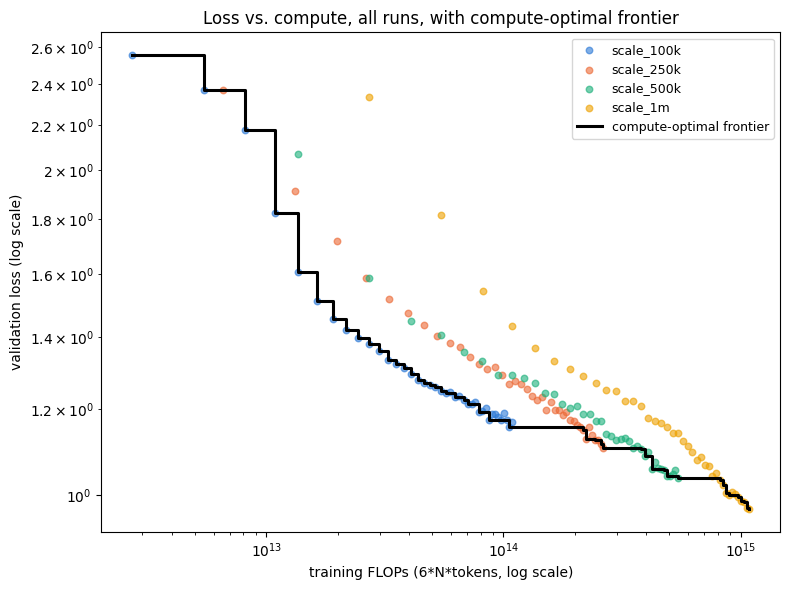

In [8]:
plt.figure(figsize=(8, 6))
for run_name, run in runs.items():
    loaded = load_run(RESULTS_DIR / run_name)
    flops_pts = [f for (_, _, f) in loaded["val"]]
    loss_pts = [l for (_, l, _) in loaded["val"]]
    plt.scatter(flops_pts, loss_pts, color=RUN_COLORS.get(run_name, "#4a3aa7"), alpha=0.6, s=22, label=run_name)

frontier = fit_results["frontier"]
frontier_flops = [p["flops"] for p in frontier]
frontier_loss = [p["loss"] for p in frontier]
plt.step(frontier_flops, frontier_loss, where="post", color="black", linewidth=2.2,
          label="compute-optimal frontier", zorder=5)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("training FLOPs (6*N*tokens, log scale)")
plt.ylabel("validation loss (log scale)")
plt.title("Loss vs. compute, all runs, with compute-optimal frontier")
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 7. Text-generation playground

Reuses week-1's `generate_text()` pattern. Same prompt, same temperature, all 4 model sizes side by side - a qualitative feel for what an extra few hundred thousand parameters actually buys you at this tiny scale, not just a loss number.

In [9]:
def generate_text(model, prompt="", max_new_tokens=300, temperature=1.0):
    """Sample from the given model. Empty prompt seeds with token id 0, same as train.py."""
    if prompt:
        unknown = set(prompt) - set(stoi)
        if unknown:
            raise ValueError(f"prompt contains characters not in the training vocab: {unknown}")
        ids = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
    else:
        ids = torch.zeros((1, 1), dtype=torch.long, device=device)
    out_ids = model.generate(ids, max_new_tokens=max_new_tokens, temperature=temperature)[0].tolist()
    return decode(out_ids)


PROMPT = "Once upon a time"
for run_name, run in runs.items():
    n_params = run["config"]["n_params"]
    print(f"--- {run_name} (N={n_params:,}) ---")
    print(generate_text(run["model"], prompt=PROMPT, max_new_tokens=250, temperature=0.8))
    print()

--- scale_100k (N=100,680) ---


Once upon a time, there was out the top! She saw it was very fish keep his friend family. The opened that carped inside? You are so need to move to play.
<|endoftext|>

Once upon a time, there was a little girl named Lily. They box dight the made him and hugged the 

--- scale_250k (N=244,032) ---


Once upon a time, there was old man and in the skip. One day knew friends. She wanted to play very happy and sweet fight main the bear and Daddy was havie. They clothes too.
Hen the animals and asked her laugh them. She said not very he didn't try to go on the rain 

--- scale_500k (N=503,720) ---


Once upon a time, there was a little girl named Lily. She liked to play with her friends. One day, they saw a safe and she was very shy and started to her.
So, they decided to look and for the botter. He ran today. Suddenly, Roding was so excited. He rooked up and s

--- scale_1m (N=1,007,600) ---


Once upon a time, there was a small and he ate a little bird. Then he heard a loud of arm. The family and he shouted and said, "That's angry have to help you to stop flowers in her best and let eddes he'd look at too," playing the competition and put it with a big s



Play with your own prompt/temperature below - change `PROMPT`, `TEMPERATURE`, or `SELECTED_RUN` and re-run.

In [10]:
SELECTED_RUN = "scale_1m"
PROMPT = "The little robot"
TEMPERATURE = 0.8

print(f"--- {SELECTED_RUN} | temperature={TEMPERATURE} ---")
print(generate_text(runs[SELECTED_RUN]["model"], prompt=PROMPT, max_new_tokens=300, temperature=TEMPERATURE))

--- scale_1m | temperature=0.8 ---


The little robot was not like the store and shouted what was wrong. As she looked, the sky. The journey was very to think and he ran over to help. 
The water was so happy and went to the bit. The baby smiled and said, "Of course! I wish skin it could take the house in here. I want every nice, understood it in a bea


## 8. Scratch space

Your own experiments below.